 # 06 - Trust-Aware Multimodal Fusion Defence Against Inference-Time Telemetry Manipulation



 **Project:** *When One Sensor Lies: Robust Multimodal Intrusion Detection Against Inference-Time Telemetry Manipulation in 5G Open RAN*



 ## 1. Research objective, leakage discipline, and threat model



 **Question.** Can an inference-time Trust-Aware Multimodal Fusion mechanism detect when one telemetry source (Network or Radio) is manipulated, down-weight the compromised sensor, and preserve detection performance without degrading clean accuracy or adding prohibitive latency?



 **Strict anti-leakage protocol:**

 - **No model is retrained.** All 18 saved checkpoints (6 architectures × 3 modalities × 5 seeds `101–505`) are loaded from `Models/deep_learning/comparison/` using `dl_comparison_models.py`.

 - **Train-only fitting:** All feature-distribution reliability estimators (Ledoit-Wolf Mahalanobis covariance, per-feature robust scales, median-imputation surprisal weights, clean entropy baselines) are fitted strictly on `partition == "train"` (2,702 windows).

 - **Validation-only calibration:** Trust decay steepness $\beta$ and uncertainty threshold $\tau_{\text{unc}}$ are calibrated strictly on `partition == "validation"` (635 windows). The primary method (`unsupervised_clean`) uses **only clean validation telemetry** (zero attack prior). An optional `validation_stress` calibration (independent seed `90901`) is evaluated solely inside the ablation suite.

 - **Frozen test evaluation:** The test partition (`partition == "test"`, 802 windows) is evaluated once under the exact 22-attack stress-test grid (`ATTACK_SEED = 20260`) from `06_inference_time_telemetry_attacks_release.ipynb` for strict apples-to-apples comparison.



 > **Synthetic stress-test disclaimer:** All perturbations are synthetic, label-independent stress tests in standardised feature space, not validated physical 5G/O-RAN attacks. No security guarantee beyond the tested threat models is claimed.



 **How to run:** Place `trust_fusion.py` and `06_trust_aware_fusion.ipynb` in the project root (next to `05_deep_learning_comparison.ipynb` and `06_inference_time_telemetry_attacks_release.ipynb`) and run *Kernel -> Restart & Run All*. Writes only to a fresh `Results/trust_aware_fusion/` directory.

 ## 2. Project root discovery, imports, and configuration

In [3]:
import sys
sys.dont_write_bytecode = True
import os, json, hashlib, platform, time, itertools
from pathlib import Path
import numpy as np
import pandas as pd

os.environ.setdefault("CUBLAS_WORKSPACE_CONFIG", ":4096:8")
import torch
import matplotlib.pyplot as plt
from IPython.display import display, Image
from sklearn.metrics import (
    accuracy_score, precision_score, recall_score, f1_score,
    roc_auc_score, average_precision_score, confusion_matrix,
)

# ---- locate project root ----
ROOT = Path.cwd()
for cand in [ROOT, *ROOT.parents]:
    if (cand / "Multimodal Datasets" / "multimodal_dataset_v2.csv").exists() and (cand / "Results" / "split_manifest.csv").exists():
        ROOT = cand
        break
else:
    raise FileNotFoundError(
        "Project root not found (expects 'Multimodal Datasets/multimodal_dataset_v2.csv' and 'Results/split_manifest.csv')."
    )

CKPT_DIR     = ROOT / "Models" / "deep_learning" / "comparison"
DLC_PATH     = CKPT_DIR / "dl_comparison_models.py"
MANIFEST_P   = ROOT / "Results" / "split_manifest.csv"
DATA_P       = ROOT / "Multimodal Datasets" / "multimodal_dataset_v2.csv"
PREP_JSON    = ROOT / "Results" / "deep_learning_comparison" / "feature_names_and_preprocessing.json"
CLEAN_PRED_P = ROOT / "Results" / "deep_learning_comparison" / "test_predictions.csv"
OUT          = ROOT / "Results" / "trust_aware_fusion"

for p in [DLC_PATH, MANIFEST_P, DATA_P, PREP_JSON, CLEAN_PRED_P]:
    assert p.exists(), f"missing project file: {p}"

sys.path.insert(0, str(ROOT))
sys.path.insert(0, str(CKPT_DIR))
import dl_comparison_models as dlc
import trust_fusion as tfm

CONFIG = {
    "threshold": 0.5,
    "repro_tolerance": 1e-6,
    "exclude_repro_failures": True,
    "eval_batch_size": 512,
    "attack_seed": 20260,          # identical to 06_inference_time_telemetry_attacks_release.ipynb
    "val_calib_seed": 90901,       # independent seed used ONLY for optional validation_stress ablation
    "latency_warmup": 3,
    "latency_repeats": 10,
}
THR = CONFIG["threshold"]
ATTACK_SEED = CONFIG["attack_seed"]

DEVICE = torch.device("cpu")
torch.set_num_threads(1)
torch.use_deterministic_algorithms(True, warn_only=False)

ARCHS = ["mlp", "cnn", "lstm", "gru", "resmlp", "ft_transformer"]
ARCH_LABEL = {
    "mlp": "MLP", "cnn": "1D CNN", "lstm": "LSTM",
    "gru": "GRU", "resmlp": "Residual MLP", "ft_transformer": "FT-Transformer",
}
ARCH_COLORS = {
    "mlp": "#4C72B0", "cnn": "#DD8452", "lstm": "#55A868",
    "gru": "#8172B3", "resmlp": "#937860", "ft_transformer": "#C44E52",
}
MODALITIES = ["network", "radio", "multimodal"]
SEEDS = [101, 202, 303, 404, 505]
METHODS = ["network_only", "radio_only", "early_fusion", "uniform_late_fusion", "trust_aware_fusion"]
METHOD_LABEL = {
    "network_only": "Network-only",
    "radio_only": "Radio-only",
    "early_fusion": "Conventional Early Fusion",
    "uniform_late_fusion": "Uniform Late Fusion (0.5/0.5)",
    "trust_aware_fusion": "Trust-Aware Fusion (Proposed)",
}
METHOD_COLORS = {
    "network_only": "#7F7F7F",
    "radio_only": "#BCBD22",
    "early_fusion": "#D62728",
    "uniform_late_fusion": "#1F77B4",
    "trust_aware_fusion": "#2CA02C",
}

if OUT.exists() and any(OUT.iterdir()):
    raise FileExistsError(f"Output directory is not empty: {OUT}; archive or remove it explicitly before rerunning.")
OUT.mkdir(parents=True, exist_ok=True)
print(f"python {platform.python_version()} | torch {torch.__version__} | device {DEVICE} | out: {OUT}")


python 3.12.6 | torch 2.15.0+cpu | device cpu | out: d:\GitHub\Robust-Multimodal-Intrusion-Detection-Against-Inference-Time-Telemetry-Manipulation-in-5G-Open-RAN\Results\trust_aware_fusion


 ## 3. Reproducibility & pre-existing file integrity fingerprints

In [4]:
def stable_seed(*parts):
    """Deterministic 32-bit seed from arbitrary parts (identical to attack notebook 06)."""
    return int.from_bytes(hashlib.sha256("|".join(map(str, parts)).encode()).digest()[:8], "little") % (2 ** 32)

def sha256_file(path):
    return hashlib.sha256(Path(path).read_bytes()).hexdigest()

ckpt_files = {(a, m): CKPT_DIR / f"{m}_{a}.pt" for a in ARCHS for m in MODALITIES}
assert all(p.exists() for p in ckpt_files.values()), "Missing one or more checkpoints"

PROTECTED = [
    MANIFEST_P, DATA_P, PREP_JSON, CLEAN_PRED_P, DLC_PATH, *ckpt_files.values(),
    ROOT / "04_baseline_models.ipynb",
    ROOT / "05_deep_learning_comparison.ipynb",
    ROOT / "06_inference_time_telemetry_attacks_release.ipynb",
]
HASH_BEFORE = {str(p.relative_to(ROOT)): sha256_file(p) for p in PROTECTED if p.exists()}
print("Protected files fingerprinted:", len(HASH_BEFORE))


Protected files fingerprinted: 26


 ## 4. Dataset, manifest splits, checkpoints, and clean reproduction check

In [5]:
df = pd.read_csv(DATA_P)
manifest = pd.read_csv(MANIFEST_P)
TARGET = "is_attack"

assert len(manifest) == len(df) and (manifest["row_index"].to_numpy() == np.arange(len(df))).all()
assert (manifest["sample_id"].to_numpy() == df["window_id"].to_numpy()).all()
assert (manifest["scenario"].to_numpy() == df["scenario"].to_numpy()).all()
assert (manifest["is_attack"].to_numpy() == df[TARGET].to_numpy()).all()
assert (manifest.groupby("scenario")["partition"].nunique() == 1).all(), "Scenario leakage across partitions!"

IDX = {part: np.flatnonzero(manifest["partition"].to_numpy() == part) for part in ["train", "validation", "test"]}
Y = {part: df[TARGET].to_numpy()[ix].astype(int) for part, ix in IDX.items()}
META_TEST = pd.DataFrame({
    "window_id": df["window_id"].to_numpy()[IDX["test"]],
    "scenario_id": df["scenario"].to_numpy()[IDX["test"]],
    "y_true": Y["test"],
    "row_index": IDX["test"],
})
SCEN_TEST = META_TEST["scenario_id"].to_numpy()
SCEN_LIST = sorted(META_TEST["scenario_id"].unique())
SCEN_IDX = {s: np.flatnonzero(SCEN_TEST == s) for s in SCEN_LIST}

for part in ["train", "validation", "test"]:
    print(f"{part:10s}: n={len(IDX[part]):4d} | attack={int(Y[part].sum()):4d} | benign={int((1 - Y[part]).sum()):4d} | scenarios={manifest.iloc[IDX[part]].scenario.nunique()}")

feat_json = json.load(open(PREP_JSON, encoding="utf-8"))
FEATURES = {m: list(feat_json["features_in_order"][m]) for m in MODALITIES}
N_FEATURES = {m: int(feat_json["n_features"][m]) for m in MODALITIES}
NET_N, RAD_N = N_FEATURES["network"], N_FEATURES["radio"]
NET_SL, RAD_SL = slice(0, NET_N), slice(NET_N, NET_N + RAD_N)
assert FEATURES["multimodal"] == FEATURES["network"] + FEATURES["radio"]

# Load all 18 checkpoints and verify preprocessing consistency
CKPTS = {}
for (a, m), p in ckpt_files.items():
    ck = dlc.load_checkpoint(p)
    assert ck["architecture"] == a and ck["modality"] == m
    assert list(ck["feature_names"]) == FEATURES[m]
    assert sorted(ck["runs"]) == SEEDS
    assert abs(float(ck["threshold"]) - THR) < 1e-12
    CKPTS[(a, m)] = ck

PREP = {m: CKPTS[("mlp", m)]["preprocessing"] for m in MODALITIES}
Z_MEDIAN = {
    b: (np.asarray(PREP[b]["median"], dtype=np.float64) - np.asarray(PREP[b]["mean"], dtype=np.float64)) / np.asarray(PREP[b]["scale"], dtype=np.float64)
    for b in ["network", "radio"]
}

# Build clean model-space tensors for train, validation, and test using SAVED preprocessing only
Z_CLEAN = {
    part: {m: dlc.apply_preprocessing(df.iloc[IDX[part]][FEATURES[m]], PREP[m]) for m in MODALITIES}
    for part in ["train", "validation", "test"]
}
for part in ["train", "validation", "test"]:
    assert np.allclose(Z_CLEAN[part]["multimodal"][:, NET_SL], Z_CLEAN[part]["network"], atol=1e-6)
    assert np.allclose(Z_CLEAN[part]["multimodal"][:, RAD_SL], Z_CLEAN[part]["radio"], atol=1e-6)

_MODELS = {}
def get_model(arch, modality, seed):
    key = (arch, modality, seed)
    if key not in _MODELS:
        _MODELS[key] = dlc.model_from_checkpoint(CKPTS[(arch, modality)], seed).to(DEVICE).eval()
    return _MODELS[key]

@torch.no_grad()
def predict_Z(arch, modality, seed, Z):
    model = get_model(arch, modality, seed)
    out = []
    bs = CONFIG["eval_batch_size"]
    for i in range(0, len(Z), bs):
        zb = torch.from_numpy(np.ascontiguousarray(Z[i:i + bs], dtype=np.float32)).to(DEVICE)
        out.append(torch.sigmoid(model(zb).double()).cpu().numpy())
    p = np.concatenate(out)
    assert p.shape == (len(Z),) and np.isfinite(p).all()
    return p

# Exact reproduction check against saved test_predictions.csv
saved = pd.read_csv(CLEAN_PRED_P)
saved = saved[saved["partition"] == "test"]
CLEAN_P_TEST, REPRO_ROWS = {}, []
for a in ARCHS:
    for m in MODALITIES:
        for s in SEEDS:
            g = saved[(saved.architecture == a) & (saved.modality == m) & (saved.seed == s)].set_index("row_index").loc[IDX["test"]]
            p = predict_Z(a, m, s, Z_CLEAN["test"][m])
            d = np.abs(p - g["y_probability"].to_numpy())
            flips = int(((p >= THR).astype(int) != g["y_pred"].to_numpy()).sum())
            ok = (d.max() <= CONFIG["repro_tolerance"]) and (flips == 0)
            REPRO_ROWS.append({"architecture": a, "modality": m, "seed": s, "max_abs_diff": float(d.max()), "flips": flips, "status": "OK" if ok else "FAILED"})
            if ok:
                CLEAN_P_TEST[(a, m, s)] = p

REPRO = pd.DataFrame(REPRO_ROWS)
print(f"Clean test reproduction OK: {(REPRO.status == 'OK').sum()}/{len(REPRO)} | worst max |diff|: {REPRO.max_abs_diff.max():.3e}")
assert (REPRO.status == "OK").all() or CONFIG["exclude_repro_failures"]

# Architectures x seeds where all three checkpoints (network, radio, multimodal) reproduced cleanly
RUNNABLE_PAIRS = [
    (a, s) for a in ARCHS for s in SEEDS
    if all((a, m, s) in CLEAN_P_TEST for m in MODALITIES)
]
print(f"Runnable (architecture, seed) triples with all 3 modalities verified: {len(RUNNABLE_PAIRS)}/{len(ARCHS) * len(SEEDS)}")

# Precompute clean train & validation predictions for network and radio models (used for fitting/calibrating trust)
CLEAN_P_TRAIN = {(a, m, s): predict_Z(a, m, s, Z_CLEAN["train"][m]) for (a, s) in RUNNABLE_PAIRS for m in ["network", "radio"]}
CLEAN_P_VAL   = {(a, m, s): predict_Z(a, m, s, Z_CLEAN["validation"][m]) for (a, s) in RUNNABLE_PAIRS for m in MODALITIES}


train     : n=2702 | attack=1924 | benign= 778 | scenarios=22
validation: n= 635 | attack= 458 | benign= 177 | scenarios=6
test      : n= 802 | attack= 573 | benign= 229 | scenarios=7
Clean test reproduction OK: 90/90 | worst max |diff|: 2.291e-07
Runnable (architecture, seed) triples with all 3 modalities verified: 30/30


 ## 5. Attack definitions (identical to `06_inference_time_telemetry_attacks_release.ipynb`)

In [6]:
FAMILY_ORDER = [
    "gaussian_noise", "bias_pos", "bias_neg", "scaling",
    "feature_corruption", "sensor_dropout_partial", "sensor_dropout_complete", "combined",
]

def build_attack_grid():
    grid = []
    def add(t, sev, rank, **params):
        grid.append({"attack_id": f"{t}|{sev}", "attack_type": t, "severity": str(sev), "severity_rank": rank, "params": params})
    for i, s in enumerate([0.1, 0.25, 0.5, 1.0]): add("gaussian_noise", s, i, sigma=s)
    for i, d in enumerate([0.5, 1.0, 2.0]): add("bias_pos", f"+{d:g}", i, delta=d, frac=0.25)
    for i, d in enumerate([0.5, 1.0, 2.0]): add("bias_neg", f"-{d:g}", i, delta=-d, frac=0.25)
    for i, c in enumerate([0.5, 2.0, 4.0]): add("scaling", f"x{c:g}", i, factor=c, frac=0.25)
    for i, f in enumerate([0.10, 0.25, 0.50]): add("feature_corruption", f"{int(f * 100)}%", i, frac=f)
    for i, f in enumerate([0.25, 0.50]): add("sensor_dropout_partial", f"{int(f * 100)}%", i, frac=f)
    add("sensor_dropout_complete", "100%", 0, frac=1.0)
    for i, (n, sg, d, f) in enumerate([("low", 0.1, 0.5, 0.10), ("medium", 0.25, 1.0, 0.25), ("high", 0.5, 2.0, 0.50)]):
        add("combined", n, i, sigma=sg, delta=d, bias_frac=0.25, corr_frac=f)
    return grid

ATTACK_GRID = build_attack_grid()
ATTACK_BY_ID = {a["attack_id"]: a for a in ATTACK_GRID}
assert len(ATTACK_GRID) == 22

def feature_subset(block, family, F, frac, seed=ATTACK_SEED):
    perm = np.random.default_rng(stable_seed(seed, block, family, "subset")).permutation(F)
    return np.sort(perm[:max(1, int(round(frac * F)))])

def perturb_block(Zb, spec, block, seed=ATTACK_SEED):
    t, p = spec["attack_type"], spec["params"]
    F = Zb.shape[1]
    Z = Zb.astype(np.float64).copy()
    noise = lambda: np.random.default_rng(stable_seed(seed, block, "noise", "eps")).standard_normal(Zb.shape)
    corr_vals = lambda: np.random.default_rng(stable_seed(seed, block, "corruption", "values")).standard_normal(Zb.shape)
    if t == "gaussian_noise":
        Z += p["sigma"] * noise()
    elif t in ("bias_pos", "bias_neg"):
        aff = feature_subset(block, "bias", F, p["frac"], seed); Z[:, aff] += p["delta"]
    elif t == "scaling":
        aff = feature_subset(block, "scaling", F, p["frac"], seed); Z[:, aff] *= p["factor"]
    elif t == "feature_corruption":
        aff = feature_subset(block, "corruption", F, p["frac"], seed); Z[:, aff] = corr_vals()[:, aff]
    elif t in ("sensor_dropout_partial", "sensor_dropout_complete"):
        aff = np.arange(F) if t == "sensor_dropout_complete" else feature_subset(block, "dropout", F, p["frac"], seed)
        Z[:, aff] = Z_MEDIAN[block][aff]
    elif t == "combined":
        ab = feature_subset(block, "bias", F, p["bias_frac"], seed); Z[:, ab] += p["delta"]
        ac = feature_subset(block, "corruption", F, p["corr_frac"], seed); Z[:, ac] = corr_vals()[:, ac]
        Z += p["sigma"] * noise()
    else:
        raise ValueError(t)
    return Z.astype(np.float32)

# Pre-generate test perturbed sensor blocks once (shared across all architectures & seeds)
PERT_TEST = {
    (block, spec["attack_id"]): perturb_block(Z_CLEAN["test"][block], spec, block, seed=ATTACK_SEED)
    for block in ["network", "radio"]
    for spec in ATTACK_GRID
}

def attacked_blocks_test(target, attack_id):
    """Return (Z_net, Z_rad, Z_multi) for test partition under (target, attack_id)."""
    zn = PERT_TEST[("network", attack_id)] if target in ("network", "both") else Z_CLEAN["test"]["network"]
    zr = PERT_TEST[("radio", attack_id)]   if target in ("radio", "both")   else Z_CLEAN["test"]["radio"]
    zm = np.concatenate([zn, zr], axis=1)
    return zn, zr, zm

# Verify exact block isolation
_zn, _zr, _zm = attacked_blocks_test("network", "gaussian_noise|0.5")
assert np.array_equal(_zr, Z_CLEAN["test"]["radio"]) and np.array_equal(_zm[:, RAD_SL], Z_CLEAN["test"]["radio"])
assert not np.array_equal(_zn, Z_CLEAN["test"]["network"])
print("Test attack blocks generated and verified:", len(PERT_TEST))


Test attack blocks generated and verified: 44


 ## 6. Metric helpers (matching notebook 06 + trust diagnostics)

In [7]:
def safe_div(a, b):
    return float(a / b) if b else float("nan")

def clf_metrics(y, p, thr=THR):
    y = np.asarray(y, dtype=int)
    p = np.asarray(p, dtype=float)
    pred = (p >= thr).astype(int)
    tn, fp, fn, tp = confusion_matrix(y, pred, labels=[0, 1]).ravel()
    both = len(np.unique(y)) == 2
    return {
        "accuracy": float(accuracy_score(y, pred)),
        "precision": float(precision_score(y, pred, pos_label=1, zero_division=0)),
        "recall": float(recall_score(y, pred, pos_label=1, zero_division=0)),
        "f1": float(f1_score(y, pred, pos_label=1, zero_division=0)),
        "macro_f1": float(f1_score(y, pred, average="macro", labels=[0, 1], zero_division=0)),
        "roc_auc": float(roc_auc_score(y, p)) if both else float("nan"),
        "pr_auc": float(average_precision_score(y, p)) if both else float("nan"),
        "fpr": safe_div(fp, fp + tn),
        "fnr": safe_div(fn, fn + tp),
        "tn": int(tn), "fp": int(fp), "fn": int(fn), "tp": int(tp),
    }

def shift_metrics(y, p_clean, p_att, thr=THR):
    y = np.asarray(y, dtype=int)
    cp = (np.asarray(p_clean) >= thr).astype(int)
    ap = (np.asarray(p_att) >= thr).astype(int)
    d = np.asarray(p_att) - np.asarray(p_clean)
    det = (y == 1) & (cp == 1)
    n_det = int(det.sum())
    n_ev = int((det & (ap == 0)).sum())
    return {
        "flip_rate": float((cp != ap).mean()),
        "mean_prob_change": float(d.mean()),
        "mean_abs_prob_change": float(np.abs(d).mean()),
        "esr_numerator": n_ev,
        "esr_denominator": n_det,
        "esr": safe_div(n_ev, n_det),
    }


 ## 7. Fit and calibrate Trust-Aware Fusion (strictly on train + validation)



 For every `(architecture, seed)` pair:

 1. Fit `TrustAwareFusion` on `Z_CLEAN["train"]` + `CLEAN_P_TRAIN` (training partition only).

 2. Calibrate `beta` and `tau_unc` via `calibrate_validation_clean` on `Z_CLEAN["validation"]` + `CLEAN_P_VAL` (clean validation partition only — **no attacks and no test data**).

In [8]:
FUSERS = {}
CALIB_ROWS = []
CLEAN_TRUST_TEST = {}  # clean test trust reference for OOD AUROC diagnostics

for (a, s) in RUNNABLE_PAIRS:
    cfg = tfm.TrustFusionConfig(
        w_mahalanobis=0.35, w_tail=0.25, w_dropout=0.25, w_confidence=0.15,
        clean_quantile=0.90, tail_top_frac=0.15, dropout_tol=1e-4,
        gamma_disagree=1.0, target_clean_val_p95_trust=0.75,
        target_clean_val_abstain=0.01, decision_threshold=THR,
    )
    fuser = tfm.TrustAwareFusion(cfg)
    fuser.fit_train(
        Z_CLEAN["train"]["network"], Z_CLEAN["train"]["radio"],
        Z_MEDIAN["network"], Z_MEDIAN["radio"],
        CLEAN_P_TRAIN[(a, "network", s)], CLEAN_P_TRAIN[(a, "radio", s)],
    )
    cal_info = fuser.calibrate_validation_clean(
        Z_CLEAN["validation"]["network"], Z_CLEAN["validation"]["radio"],
        CLEAN_P_VAL[(a, "network", s)], CLEAN_P_VAL[(a, "radio", s)],
    )
    FUSERS[(a, s)] = fuser
    CALIB_ROWS.append({"architecture": a, "seed": s, **cal_info})

    # Clean test evaluation (no fitting/tuning!)
    out_clean = fuser.fuse(
        Z_CLEAN["test"]["network"], Z_CLEAN["test"]["radio"],
        CLEAN_P_TEST[(a, "network", s)], CLEAN_P_TEST[(a, "radio", s)],
    )
    CLEAN_TRUST_TEST[(a, s)] = out_clean

CALIB_DF = pd.DataFrame(CALIB_ROWS)
CALIB_DF.to_csv(OUT / "validation_calibration_summary.csv", index=False)
display(CALIB_DF.groupby("architecture")[["beta_calibrated", "tau_unc_calibrated", "clean_val_trust_net_mean", "clean_val_trust_rad_mean", "clean_val_abstain_rate"]].mean().round(4))


,beta_calibrated,tau_unc_calibrated,clean_val_trust_net_mean,clean_val_trust_rad_mean,clean_val_abstain_rate
architecture,,,,,
cnn,0.35,0.4500,0.7946,0.9505,0.0031
ft_transformer,0.35,0.4212,0.8254,0.9404,0.0057
gru,0.35,0.4446,0.8197,0.9420,0.0060
lstm,0.35,0.4500,0.8178,0.9450,0.0047
mlp,0.35,0.3881,0.8226,0.9255,0.0069
resmlp,0.35,0.3801,0.8165,0.9227,0.0072


 ## 8. Clean-data comparison (RQ5: cost of defence on clean telemetry)

In [9]:
CLEAN_COMP_ROWS = []
CLEAN_METHOD_P = {}  # (method, arch, seed) -> clean test probabilities

for (a, s) in RUNNABLE_PAIRS:
    pn = CLEAN_P_TEST[(a, "network", s)]
    pr = CLEAN_P_TEST[(a, "radio", s)]
    pm = CLEAN_P_TEST[(a, "multimodal", s)]
    pl, _ = tfm.uniform_late_fusion(pn, pr, threshold=THR)
    out_tf = CLEAN_TRUST_TEST[(a, s)]
    pt = out_tf.p_fused

    for mname, prob in [
        ("network_only", pn),
        ("radio_only", pr),
        ("early_fusion", pm),
        ("uniform_late_fusion", pl),
        ("trust_aware_fusion", pt),
    ]:
        CLEAN_METHOD_P[(mname, a, s)] = prob
        row = {"method": mname, "architecture": a, "seed": s, **clf_metrics(Y["test"], prob)}
        if mname == "trust_aware_fusion":
            row.update(tfm.trust_diagnostic_metrics(out_tf, "clean"))
            row.update(tfm.selective_metrics(Y["test"], out_tf, threshold=THR))
        CLEAN_COMP_ROWS.append(row)

CLEAN_COMP = pd.DataFrame(CLEAN_COMP_ROWS)
CLEAN_COMP.to_csv(OUT / "clean_comparison_per_seed.csv", index=False)
clean_tbl = CLEAN_COMP.groupby(["architecture", "method"])[["accuracy", "macro_f1", "recall", "fpr", "pr_auc", "abstain_rate"]].mean().unstack("method")
display(clean_tbl["macro_f1"][METHODS].reindex(ARCHS).rename(index=ARCH_LABEL).round(4))


method,network_only,radio_only,early_fusion,uniform_late_fusion,trust_aware_fusion
architecture,,,,,
MLP,0.9954,0.9939,0.9988,1.0000,0.9969
1D CNN,0.8712,0.9879,0.9753,0.9915,0.9932
LSTM,0.9651,0.9954,0.9937,0.9948,0.9966
GRU,0.9637,0.9942,0.9917,0.9939,0.9963
Residual MLP,0.9951,0.9896,0.9985,0.9985,0.9969
FT-Transformer,0.9906,0.9921,0.9997,0.9982,0.9966


 ## 9. Main robustness experiment: all 5 methods × 6 architectures × 5 seeds × 22 attacks × 3 targets

In [10]:
t0 = time.perf_counter()
MAIN_ROWS = []
SCEN_ROWS = []

# Cache attacked single-modality and early-fusion probabilities per (arch, seed, target, attack_id)
# so ablations reuse the exact forward passes without redundant neural-network inference.
ATT_PROB_CACHE = {}

for attack in ATTACK_GRID:
    aid = attack["attack_id"]
    for target in ["network", "radio", "both"]:
        zn, zr, zm = attacked_blocks_test(target, aid)
        for (a, s) in RUNNABLE_PAIRS:
            # Predict under manipulation (or reuse clean prediction if that sensor was untouched)
            pn = predict_Z(a, "network", s, zn) if target in ("network", "both") else CLEAN_P_TEST[(a, "network", s)]
            pr = predict_Z(a, "radio", s, zr)   if target in ("radio", "both")   else CLEAN_P_TEST[(a, "radio", s)]
            pm = predict_Z(a, "multimodal", s, zm)
            ATT_PROB_CACHE[(a, s, target, aid)] = (pn, pr, pm)

            pl, _ = tfm.uniform_late_fusion(pn, pr, threshold=THR)
            out_tf = FUSERS[(a, s)].fuse(zn, zr, pn, pr)
            pt = out_tf.p_fused

            clean_ref = CLEAN_TRUST_TEST[(a, s)]
            tdiag = tfm.trust_diagnostic_metrics(out_tf, target, clean_ref.trust_network, clean_ref.trust_radio)
            smet  = tfm.selective_metrics(Y["test"], out_tf, threshold=THR)

            base = {
                "architecture": a, "seed": s, "attack_target": target,
                "attack_type": attack["attack_type"], "severity": attack["severity"],
                "severity_rank": attack["severity_rank"], "attack_id": aid,
            }
            for mname, prob in [
                ("network_only", pn),
                ("radio_only", pr),
                ("early_fusion", pm),
                ("uniform_late_fusion", pl),
                ("trust_aware_fusion", pt),
            ]:
                pc = CLEAN_METHOD_P[(mname, a, s)]
                row = {
                    **base, "method": mname, "n_test": len(Y["test"]),
                    **clf_metrics(Y["test"], prob),
                    **shift_metrics(Y["test"], pc, prob),
                }
                if mname == "trust_aware_fusion":
                    row.update(tdiag)
                    row.update(smet)
                MAIN_ROWS.append(row)

            # Scenario-level comparison for Early Fusion vs Uniform Late vs Trust-Aware Fusion
            for mname, prob in [("early_fusion", pm), ("uniform_late_fusion", pl), ("trust_aware_fusion", pt)]:
                pc = CLEAN_METHOD_P[(mname, a, s)]
                for scen, ix in SCEN_IDX.items():
                    yy, p_c, p_a = Y["test"][ix], pc[ix], prob[ix]
                    cp, ap = (p_c >= THR).astype(int), (p_a >= THR).astype(int)
                    det = (yy == 1) & (cp == 1); nd = int(det.sum()); ne = int((det & (ap == 0)).sum())
                    SCEN_ROWS.append({
                        **base, "method": mname, "scenario_id": scen,
                        "class": "attack" if yy.max() == 1 else "benign", "n_windows": len(ix),
                        "attacked_accuracy": float((ap == yy).mean()),
                        "esr": safe_div(ne, nd), "flip_rate": float((cp != ap).mean()),
                    })

MAIN_DF = pd.DataFrame(MAIN_ROWS)
clean_join = CLEAN_COMP.set_index(["method", "architecture", "seed"])[["macro_f1", "recall", "fpr", "fnr", "accuracy"]].add_prefix("clean_")
MAIN_DF = MAIN_DF.join(clean_join, on=["method", "architecture", "seed"])
for k in ["macro_f1", "recall", "fpr", "fnr", "accuracy"]:
    MAIN_DF[f"delta_{k}"] = MAIN_DF[k] - MAIN_DF[f"clean_{k}"]

MAIN_DF.to_csv(OUT / "trust_fusion_results_per_seed.csv", index=False)
SCEN_DF = pd.DataFrame(SCEN_ROWS)
SCEN_DF.to_csv(OUT / "trust_fusion_scenario_results.csv", index=False)

# Summary table: mean +/- std over seeds per (method, architecture, target, attack)
SUM_KEYS = ["method", "architecture", "attack_target", "attack_type", "severity", "severity_rank", "attack_id"]
SUM_COLS = ["accuracy", "macro_f1", "recall", "precision", "fpr", "fnr", "roc_auc", "pr_auc", "esr", "flip_rate",
            "delta_macro_f1", "cmia", "trust_gap", "sensor_ood_auroc", "abstain_rate", "selective_macro_f1"]
g = MAIN_DF.groupby(SUM_KEYS, sort=False)
SUMMARY_DF = g[SUM_COLS].mean().add_suffix("_mean").join(g[SUM_COLS].std(ddof=1).add_suffix("_std")).reset_index()
SUMMARY_DF.to_csv(OUT / "trust_fusion_results_summary.csv", index=False)

print(f"Main experiment completed in {time.perf_counter() - t0:.1f}s | rows: {len(MAIN_DF):,}")

# Headline table: mean Macro-F1 across all 22 attacks, per target and method
COND_SEED = (
    MAIN_DF.groupby(["method", "architecture", "attack_target", "seed"])
    .agg(
        clean_macro_f1=("clean_macro_f1", "first"),
        macro_f1=("macro_f1", "mean"),
        worst_macro_f1=("macro_f1", "min"),
        delta_macro_f1=("delta_macro_f1", "mean"),
        recall=("recall", "mean"),
        fpr=("fpr", "mean"),
        esr=("esr", "mean"),
        cmia=("cmia", "mean"),
        trust_gap=("trust_gap", "mean"),
        sensor_ood_auroc=("sensor_ood_auroc", "mean"),
        abstain_rate=("abstain_rate", "mean"),
        selective_macro_f1=("selective_macro_f1", "mean"),
    ).reset_index()
)
COND_SEED.to_csv(OUT / "trust_fusion_condition_summary_per_seed.csv", index=False)

for tgt in ["network", "radio", "both"]:
    print(f"\n=== Target manipulated: {tgt.upper()} (Mean Macro-F1 across 22 attacks, averaged over 5 seeds) ===")
    piv = COND_SEED[COND_SEED.attack_target == tgt].groupby(["architecture", "method"])["macro_f1"].mean().unstack("method")[METHODS].reindex(ARCHS)
    piv["gain_vs_early"] = piv["trust_aware_fusion"] - piv["early_fusion"]
    piv["gain_vs_uniform_late"] = piv["trust_aware_fusion"] - piv["uniform_late_fusion"]
    display(piv.rename(index=ARCH_LABEL).round(4))


Main experiment completed in 396.7s | rows: 9,900

=== Target manipulated: NETWORK (Mean Macro-F1 across 22 attacks, averaged over 5 seeds) ===


method,network_only,radio_only,early_fusion,uniform_late_fusion,trust_aware_fusion,gain_vs_early,gain_vs_uniform_late
architecture,,,,,,,
MLP,0.9198,0.9939,0.9749,0.9971,0.9953,0.0204,-0.0018
1D CNN,0.8063,0.9879,0.9111,0.9377,0.9904,0.0793,0.0527
LSTM,0.8318,0.9954,0.9141,0.9476,0.9957,0.0815,0.0480
GRU,0.7921,0.9942,0.9075,0.9464,0.9950,0.0875,0.0486
Residual MLP,0.9180,0.9896,0.9794,0.9955,0.9934,0.0140,-0.0021
FT-Transformer,0.8839,0.9921,0.9633,0.9730,0.9941,0.0308,0.0211



=== Target manipulated: RADIO (Mean Macro-F1 across 22 attacks, averaged over 5 seeds) ===


method,network_only,radio_only,early_fusion,uniform_late_fusion,trust_aware_fusion,gain_vs_early,gain_vs_uniform_late
architecture,,,,,,,
MLP,0.9954,0.8943,0.9971,0.9921,0.9965,-0.0006,0.0044
1D CNN,0.8712,0.8446,0.9111,0.9579,0.9438,0.0327,-0.0141
LSTM,0.9651,0.8986,0.9862,0.9706,0.9814,-0.0048,0.0108
GRU,0.9637,0.8828,0.9733,0.9620,0.9851,0.0117,0.0231
Residual MLP,0.9951,0.8835,0.9974,0.9915,0.9962,-0.0012,0.0048
FT-Transformer,0.9906,0.8894,0.9971,0.9670,0.9941,-0.0030,0.0271



=== Target manipulated: BOTH (Mean Macro-F1 across 22 attacks, averaged over 5 seeds) ===


method,network_only,radio_only,early_fusion,uniform_late_fusion,trust_aware_fusion,gain_vs_early,gain_vs_uniform_late
architecture,,,,,,,
MLP,0.9198,0.8943,0.9394,0.9382,0.9345,-0.0049,-0.0037
1D CNN,0.8063,0.8446,0.8165,0.8879,0.8807,0.0642,-0.0072
LSTM,0.8318,0.8986,0.8825,0.8919,0.8968,0.0143,0.0049
GRU,0.7921,0.8828,0.8685,0.8775,0.8916,0.0231,0.0140
Residual MLP,0.9180,0.8835,0.9455,0.9365,0.9298,-0.0157,-0.0068
FT-Transformer,0.8839,0.8894,0.9184,0.9183,0.9115,-0.0069,-0.0068


 ## 10. Ablation study (Proposal Section 8.5)



 Evaluates:

 1. Each individual reliability indicator (`mahalanobis_only`, `tail_only`, `dropout_only`, `confidence_only`)

 2. Removing the median-imputation dropout detector (`no_dropout_indicator`) — demonstrates why dropout surprisal is essential for Attacks E1/E2

 3. Pure input-space reliability (`input_only_no_confidence`)

 4. Disabling the disagreement-gated sharpening (`no_disagreement_gate`)

 5. Optional `validation_stress` calibration (independent validation seed `90901`) vs default `unsupervised_clean`

In [11]:
ABL_ROWS = []

# Build optional validation-only stress batches (independent seed 90901, strictly validation partition)
VAL_STRESS_SUBSET = ["gaussian_noise|0.5", "bias_pos|+1", "scaling|x2", "feature_corruption|25%", "sensor_dropout_partial|50%", "sensor_dropout_complete|100%"]
VAL_PERT = {
    (b, aid): perturb_block(Z_CLEAN["validation"][b], ATTACK_BY_ID[aid], b, seed=CONFIG["val_calib_seed"])
    for b in ["network", "radio"] for aid in VAL_STRESS_SUBSET
}

# Fit optional validation-stress calibrated fusers (per architecture, seed)
STRESS_FUSERS = {}
for (a, s) in RUNNABLE_PAIRS:
    batches = []
    for aid in VAL_STRESS_SUBSET:
        for tgt in ["network", "radio"]:
            zn_v = VAL_PERT[("network", aid)] if tgt == "network" else Z_CLEAN["validation"]["network"]
            zr_v = VAL_PERT[("radio", aid)]   if tgt == "radio"   else Z_CLEAN["validation"]["radio"]
            pn_v = predict_Z(a, "network", s, zn_v) if tgt == "network" else CLEAN_P_VAL[(a, "network", s)]
            pr_v = predict_Z(a, "radio", s, zr_v)   if tgt == "radio"   else CLEAN_P_VAL[(a, "radio", s)]
            batches.append({"Z_net": zn_v, "Z_rad": zr_v, "p_net": pn_v, "p_rad": pr_v, "target": tgt})
    sf = tfm.TrustAwareFusion(tfm.TrustFusionConfig(decision_threshold=THR))
    sf.fit_train(
        Z_CLEAN["train"]["network"], Z_CLEAN["train"]["radio"],
        Z_MEDIAN["network"], Z_MEDIAN["radio"],
        CLEAN_P_TRAIN[(a, "network", s)], CLEAN_P_TRAIN[(a, "radio", s)],
    )
    sf.calibrate_validation_stress(
        Y["validation"], Z_CLEAN["validation"]["network"], Z_CLEAN["validation"]["radio"],
        CLEAN_P_VAL[(a, "network", s)], CLEAN_P_VAL[(a, "radio", s)], batches,
    )
    STRESS_FUSERS[(a, s)] = sf

# Evaluate all ablation presets + validation_stress using cached attacked probabilities
for preset_name, params in tfm.ABLATION_PRESETS.items():
    w_dict = {
        "mahalanobis": params["w_mahalanobis"],
        "tail": params["w_tail"],
        "dropout": params["w_dropout"],
        "confidence": params["w_confidence"],
    }
    w_sum = sum(w_dict.values())
    w_norm = {k: v / w_sum for k, v in w_dict.items()}
    gamma = params["gamma_disagree"]

    for (a, s) in RUNNABLE_PAIRS:
        # Clean check
        oc = FUSERS[(a, s)].fuse(
            Z_CLEAN["test"]["network"], Z_CLEAN["test"]["radio"],
            CLEAN_P_TEST[(a, "network", s)], CLEAN_P_TEST[(a, "radio", s)],
            gamma_override=gamma, weights_override=w_norm,
        )
        ABL_ROWS.append({
            "ablation": preset_name, "architecture": a, "seed": s, "attack_target": "clean",
            "attack_type": "clean", "attack_id": "clean",
            **clf_metrics(Y["test"], oc.p_fused),
            "cmia": float("nan"), "abstain_rate": float(np.mean(oc.is_uncertain)),
        })
        for attack in ATTACK_GRID:
            aid = attack["attack_id"]
            for tgt in ["network", "radio", "both"]:
                zn, zr, _ = attacked_blocks_test(tgt, aid)
                pn, pr, _ = ATT_PROB_CACHE[(a, s, tgt, aid)]
                o = FUSERS[(a, s)].fuse(zn, zr, pn, pr, gamma_override=gamma, weights_override=w_norm)
                td = tfm.trust_diagnostic_metrics(o, tgt)
                ABL_ROWS.append({
                    "ablation": preset_name, "architecture": a, "seed": s, "attack_target": tgt,
                    "attack_type": attack["attack_type"], "attack_id": aid,
                    **clf_metrics(Y["test"], o.p_fused),
                    "cmia": td["cmia"], "abstain_rate": td["abstain_rate"],
                })

# Add validation_stress ablation variant
for (a, s) in RUNNABLE_PAIRS:
    oc = STRESS_FUSERS[(a, s)].fuse(
        Z_CLEAN["test"]["network"], Z_CLEAN["test"]["radio"],
        CLEAN_P_TEST[(a, "network", s)], CLEAN_P_TEST[(a, "radio", s)],
    )
    ABL_ROWS.append({
        "ablation": "validation_stress_calibrated", "architecture": a, "seed": s, "attack_target": "clean",
        "attack_type": "clean", "attack_id": "clean",
        **clf_metrics(Y["test"], oc.p_fused), "cmia": float("nan"), "abstain_rate": float(np.mean(oc.is_uncertain)),
    })
    for attack in ATTACK_GRID:
        aid = attack["attack_id"]
        for tgt in ["network", "radio", "both"]:
            zn, zr, _ = attacked_blocks_test(tgt, aid)
            pn, pr, _ = ATT_PROB_CACHE[(a, s, tgt, aid)]
            o = STRESS_FUSERS[(a, s)].fuse(zn, zr, pn, pr)
            td = tfm.trust_diagnostic_metrics(o, tgt)
            ABL_ROWS.append({
                "ablation": "validation_stress_calibrated", "architecture": a, "seed": s, "attack_target": tgt,
                "attack_type": attack["attack_type"], "attack_id": aid,
                **clf_metrics(Y["test"], o.p_fused), "cmia": td["cmia"], "abstain_rate": td["abstain_rate"],
            })

ABL_DF = pd.DataFrame(ABL_ROWS)
ABL_DF.to_csv(OUT / "ablation_results_per_seed.csv", index=False)

abl_summary = ABL_DF.groupby(["ablation", "attack_target"])[["macro_f1", "recall", "cmia", "abstain_rate"]].mean().unstack("attack_target")
display(abl_summary["macro_f1"][["clean", "network", "radio", "both"]].round(4))

# Highlight sensor-dropout attacks specifically to show impact of median-surprisal indicator
drop_abl = ABL_DF[ABL_DF.attack_type.isin(["sensor_dropout_partial", "sensor_dropout_complete"]) & ABL_DF.attack_target.isin(["network", "radio"])]
display(drop_abl.groupby(["ablation", "attack_target"])[["macro_f1", "cmia"]].mean().unstack("attack_target").round(4))


attack_target,clean,network,radio,both
ablation,,,,
confidence_only,0.9976,0.9742,0.9789,0.9121
dropout_only,0.9956,0.9688,0.9713,0.9050
full_trust,0.9961,0.9940,0.9829,0.9075
input_only_no_confidence,0.9950,0.9932,0.9743,0.8930
mahalanobis_only,0.9946,0.9927,0.9716,0.8808
no_disagreement_gate,0.9961,0.9943,0.9838,0.9083
no_dropout_indicator,0.9960,0.9938,0.9817,0.9071
tail_only,0.9896,0.9718,0.9613,0.8937
validation_stress_calibrated,0.9960,0.9943,0.9833,0.9068


macro_f1            cmia        
attack_target                 network   radio network   radio
ablation                                                     
confidence_only                0.9762  0.9793  0.4205  0.5085
dropout_only                   0.9935  0.9637  0.6820  1.0000
full_trust                     0.9932  0.9715  0.9347  0.9773
input_only_no_confidence       0.9928  0.9635  0.9277  0.9842
mahalanobis_only               0.9926  0.9481  0.9235  0.8599
no_disagreement_gate           0.9934  0.9727  0.9347  0.9773
no_dropout_indicator           0.9931  0.9637  0.9300  0.8469
tail_only                      0.9391  0.9424  0.0424  0.0025
validation_stress_calibrated   0.9934  0.9720  0.9347  0.9773

 ## 11. Hyperparameter sensitivity analysis ($\beta$ and $\tau_{\text{unc}}$)

In [12]:
BETA_SWEEP = [0.1, 0.25, 0.5, 0.75, 1.0, 1.5, 2.5, 4.0]
TAU_SWEEP  = [0.05, 0.10, 0.20, 0.30, 0.40, 0.50, 0.65]
SENS_BETA_ROWS, SENS_TAU_ROWS = [], []

# Run on primary seed of each architecture across all 22 attacks (fast & clean sensitivity curve)
PRIMARY_SEEDS = {a: CKPTS[(a, "multimodal")]["primary_seed"] for a in ARCHS}

for beta in BETA_SWEEP:
    for a in ARCHS:
        s = PRIMARY_SEEDS[a]
        # Clean
        oc = FUSERS[(a, s)].fuse(
            Z_CLEAN["test"]["network"], Z_CLEAN["test"]["radio"],
            CLEAN_P_TEST[(a, "network", s)], CLEAN_P_TEST[(a, "radio", s)],
            beta_override=beta,
        )
        SENS_BETA_ROWS.append({"beta": beta, "architecture": a, "attack_target": "clean", "macro_f1": clf_metrics(Y["test"], oc.p_fused)["macro_f1"], "cmia": float("nan")})
        for tgt in ["network", "radio", "both"]:
            f1s, cmias = [], []
            for attack in ATTACK_GRID:
                aid = attack["attack_id"]
                zn, zr, _ = attacked_blocks_test(tgt, aid)
                pn, pr, _ = ATT_PROB_CACHE[(a, s, tgt, aid)]
                o = FUSERS[(a, s)].fuse(zn, zr, pn, pr, beta_override=beta)
                f1s.append(clf_metrics(Y["test"], o.p_fused)["macro_f1"])
                cmias.append(tfm.trust_diagnostic_metrics(o, tgt)["cmia"])
            SENS_BETA_ROWS.append({"beta": beta, "architecture": a, "attack_target": tgt, "macro_f1": float(np.mean(f1s)), "cmia": float(np.nanmean(cmias))})

for tau in TAU_SWEEP:
    for a in ARCHS:
        s = PRIMARY_SEEDS[a]
        oc = FUSERS[(a, s)].fuse(
            Z_CLEAN["test"]["network"], Z_CLEAN["test"]["radio"],
            CLEAN_P_TEST[(a, "network", s)], CLEAN_P_TEST[(a, "radio", s)],
            tau_unc_override=tau,
        )
        sm_c = tfm.selective_metrics(Y["test"], oc, threshold=THR)
        SENS_TAU_ROWS.append({"tau_unc": tau, "architecture": a, "attack_target": "clean", **sm_c})
        for tgt in ["network", "radio", "both"]:
            covs, sf1s = [], []
            for attack in ATTACK_GRID:
                aid = attack["attack_id"]
                zn, zr, _ = attacked_blocks_test(tgt, aid)
                pn, pr, _ = ATT_PROB_CACHE[(a, s, tgt, aid)]
                o = FUSERS[(a, s)].fuse(zn, zr, pn, pr, tau_unc_override=tau)
                sm = tfm.selective_metrics(Y["test"], o, threshold=THR)
                covs.append(sm["coverage"]); sf1s.append(sm["selective_macro_f1"])
            SENS_TAU_ROWS.append({
                "tau_unc": tau, "architecture": a, "attack_target": tgt,
                "coverage": float(np.mean(covs)), "abstain_rate": 1.0 - float(np.mean(covs)),
                "selective_macro_f1": float(np.nanmean(sf1s)),
            })

SENS_BETA_DF = pd.DataFrame(SENS_BETA_ROWS)
SENS_TAU_DF  = pd.DataFrame(SENS_TAU_ROWS)
SENS_BETA_DF.to_csv(OUT / "sensitivity_beta.csv", index=False)
SENS_TAU_DF.to_csv(OUT / "sensitivity_tau_unc.csv", index=False)
display(SENS_BETA_DF.groupby(["beta", "attack_target"])["macro_f1"].mean().unstack("attack_target").round(4))
display(SENS_TAU_DF.groupby(["tau_unc", "attack_target"])[["abstain_rate", "selective_macro_f1"]].mean().unstack("attack_target").round(4))


C:\Users\treex\AppData\Local\Temp\ipykernel_24940\3529768734.py:27: RuntimeWarning: Mean of empty slice
  SENS_BETA_ROWS.append({"beta": beta, "architecture": a, "attack_target": tgt, "macro_f1": float(np.mean(f1s)), "cmia": float(np.nanmean(cmias))})
C:\Users\treex\AppData\Local\Temp\ipykernel_24940\3529768734.py:27: RuntimeWarning: Mean of empty slice
  SENS_BETA_ROWS.append({"beta": beta, "architecture": a, "attack_target": tgt, "macro_f1": float(np.mean(f1s)), "cmia": float(np.nanmean(cmias))})
C:\Users\treex\AppData\Local\Temp\ipykernel_24940\3529768734.py:27: RuntimeWarning: Mean of empty slice
  SENS_BETA_ROWS.append({"beta": beta, "architecture": a, "attack_target": tgt, "macro_f1": float(np.mean(f1s)), "cmia": float(np.nanmean(cmias))})
C:\Users\treex\AppData\Local\Temp\ipykernel_24940\3529768734.py:27: RuntimeWarning: Mean of empty slice
  SENS_BETA_ROWS.append({"beta": beta, "architecture": a, "attack_target": tgt, "macro_f1": float(np.mean(f1s)), "cmia": float(np.nanmean(cm

attack_target,both,clean,network,radio
beta,,,,
0.10,0.9067,0.9967,0.9944,0.9934
0.25,0.9057,0.9962,0.9936,0.9930
0.50,0.9050,0.9959,0.9929,0.9925
0.75,0.9045,0.9954,0.9926,0.9922
1.00,0.9042,0.9954,0.9924,0.9919
1.50,0.9056,0.9949,0.9923,0.9917
2.50,0.9002,0.9949,0.9922,0.9934
4.00,0.9003,0.9946,0.9917,0.9919


abstain_rate                         selective_macro_f1          \
attack_target         both   clean network   radio               both   clean   
tau_unc                                                                         
0.05                0.0567  0.0000  0.0000  0.0029             0.9178  0.9959   
0.10                0.1430  0.0000  0.0000  0.0160             0.9430  0.9959   
0.20                0.2980  0.0000  0.0001  0.0377             0.9504  0.9959   
0.30                0.4799  0.0012  0.0029  0.0614             0.9527  0.9962   
0.40                0.5449  0.0039  0.0084  0.1226             0.9419  0.9961   
0.50                0.6233  0.0067  0.0174  0.1452             0.9450  0.9961   
0.65                0.7176  0.0108  0.0286  0.1705             0.9313  0.9966   

                               
attack_target network   radio  
tau_unc                        
0.05           0.9932  0.9935  
0.10           0.9932  0.9960  
0.20           0.9932  0.9978  
0.30           0.9946  0.9985  
0.40           0.9953  0.9988  
0.50           0.9954  0.9993  
0.65           0.9963  0.9994

 ## 12. Inference latency & computational overhead benchmark (RQ5)

In [13]:
LAT_ROWS = []
zn_bench = Z_CLEAN["test"]["network"]
zr_bench = Z_CLEAN["test"]["radio"]
zm_bench = Z_CLEAN["test"]["multimodal"]
n_win = len(zn_bench)

for a in ARCHS:
    s = PRIMARY_SEEDS[a]
    fuser = FUSERS[(a, s)]

    # Warm-up
    for _ in range(CONFIG["latency_warmup"]):
        _ = predict_Z(a, "multimodal", s, zm_bench)
        _pn = predict_Z(a, "network", s, zn_bench)
        _pr = predict_Z(a, "radio", s, zr_bench)
        _ = fuser.fuse(zn_bench, zr_bench, _pn, _pr)

    t_early, t_late, t_trust_only, t_trust_total = [], [], [], []
    for _ in range(CONFIG["latency_repeats"]):
        t0 = time.perf_counter()
        _ = predict_Z(a, "multimodal", s, zm_bench)
        t_early.append((time.perf_counter() - t0) * 1e3)

        t0 = time.perf_counter()
        pn = predict_Z(a, "network", s, zn_bench)
        pr = predict_Z(a, "radio", s, zr_bench)
        _ = tfm.uniform_late_fusion(pn, pr, THR)
        t_late.append((time.perf_counter() - t0) * 1e3)

        t0 = time.perf_counter()
        _ = fuser.fuse(zn_bench, zr_bench, pn, pr)
        dt_trust = (time.perf_counter() - t0) * 1e3
        t_trust_only.append(dt_trust)
        t_trust_total.append(t_late[-1] + dt_trust)

    LAT_ROWS.append({
        "architecture": a, "n_windows": n_win,
        "early_fusion_batch_ms_mean": float(np.mean(t_early)),
        "early_fusion_batch_ms_std": float(np.std(t_early, ddof=1)),
        "uniform_late_batch_ms_mean": float(np.mean(t_late)),
        "trust_scoring_only_batch_ms_mean": float(np.mean(t_trust_only)),
        "trust_fusion_total_batch_ms_mean": float(np.mean(t_trust_total)),
        "trust_fusion_total_batch_ms_std": float(np.std(t_trust_total, ddof=1)),
        "early_fusion_us_per_window": float(np.mean(t_early) * 1e3 / n_win),
        "trust_scoring_us_per_window": float(np.mean(t_trust_only) * 1e3 / n_win),
        "trust_fusion_total_us_per_window": float(np.mean(t_trust_total) * 1e3 / n_win),
        "overhead_vs_early_ratio": float(np.mean(t_trust_total) / np.mean(t_early)),
        "trust_overhead_vs_late_pct": float(100.0 * np.mean(t_trust_only) / np.mean(t_late)),
    })

LAT_DF = pd.DataFrame(LAT_ROWS)
LAT_DF.to_csv(OUT / "inference_latency_benchmark.csv", index=False)
display(LAT_DF[["architecture", "early_fusion_us_per_window", "trust_scoring_us_per_window", "trust_fusion_total_us_per_window", "overhead_vs_early_ratio", "trust_overhead_vs_late_pct"]].round(2))


,architecture,early_fusion_us_per_window,trust_scoring_us_per_window,trust_fusion_total_us_per_window,overhead_vs_early_ratio,trust_overhead_vs_late_pct
0,mlp,2.12,2.11,5.77,2.73,57.59
1,cnn,39.50,2.42,40.82,1.03,6.29
2,lstm,66.05,2.95,73.46,1.11,4.18
3,gru,88.55,2.44,73.83,0.83,3.41
4,resmlp,2.83,2.09,7.54,2.67,38.42
5,ft_transformer,472.10,2.38,402.22,0.85,0.59


 ## 13. Visualizations

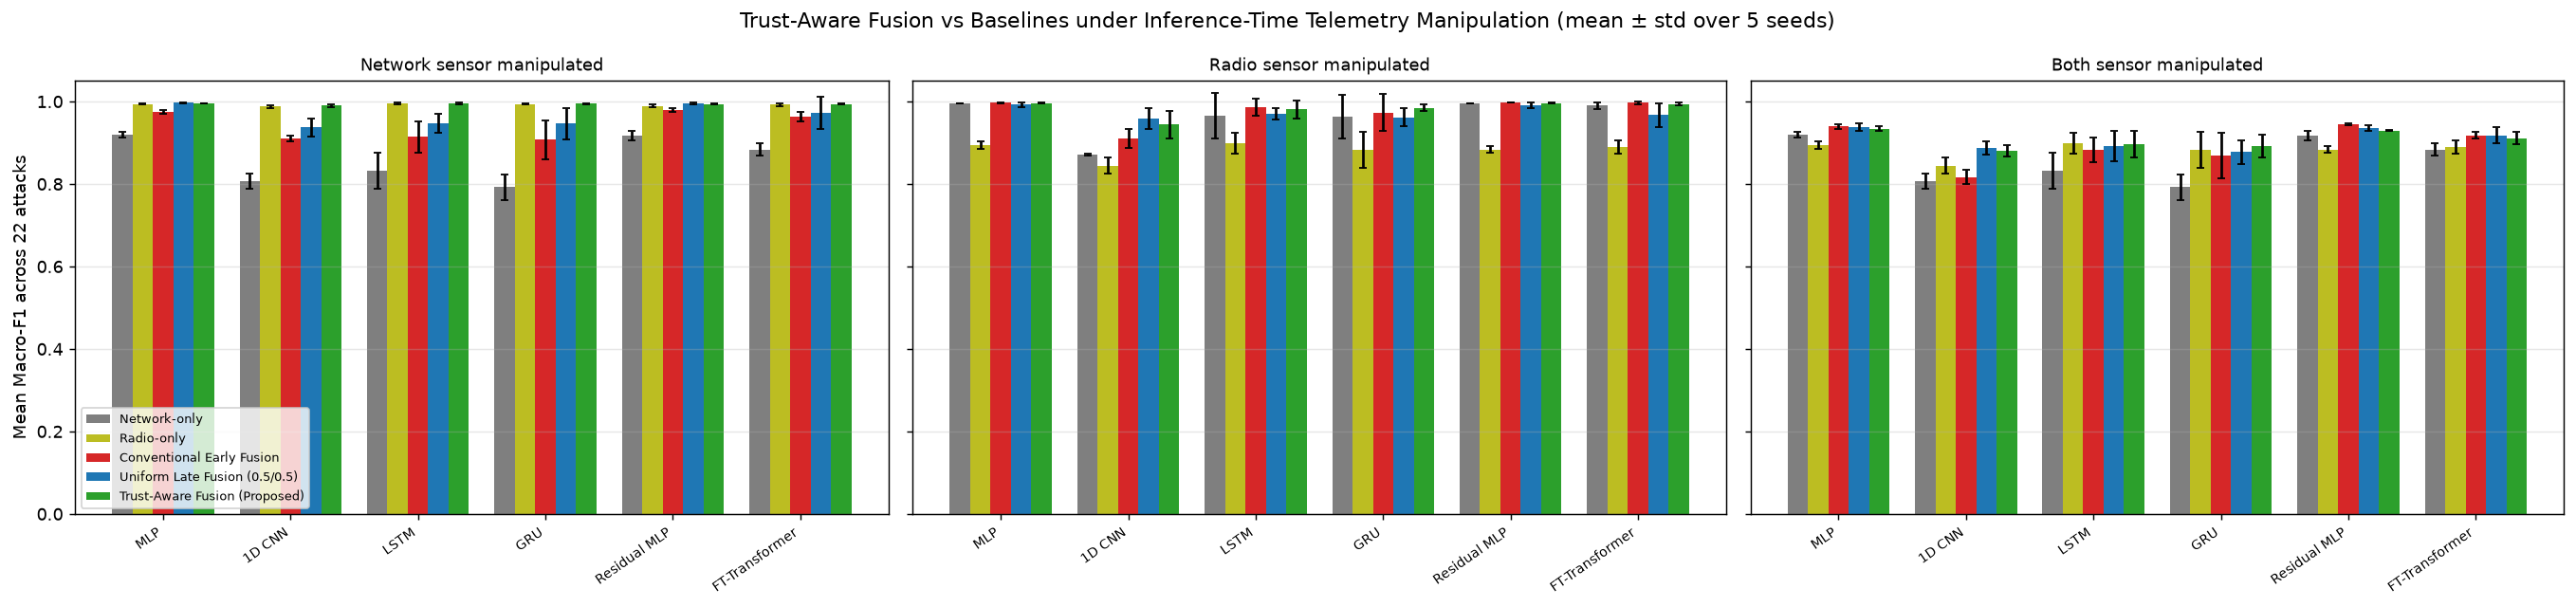

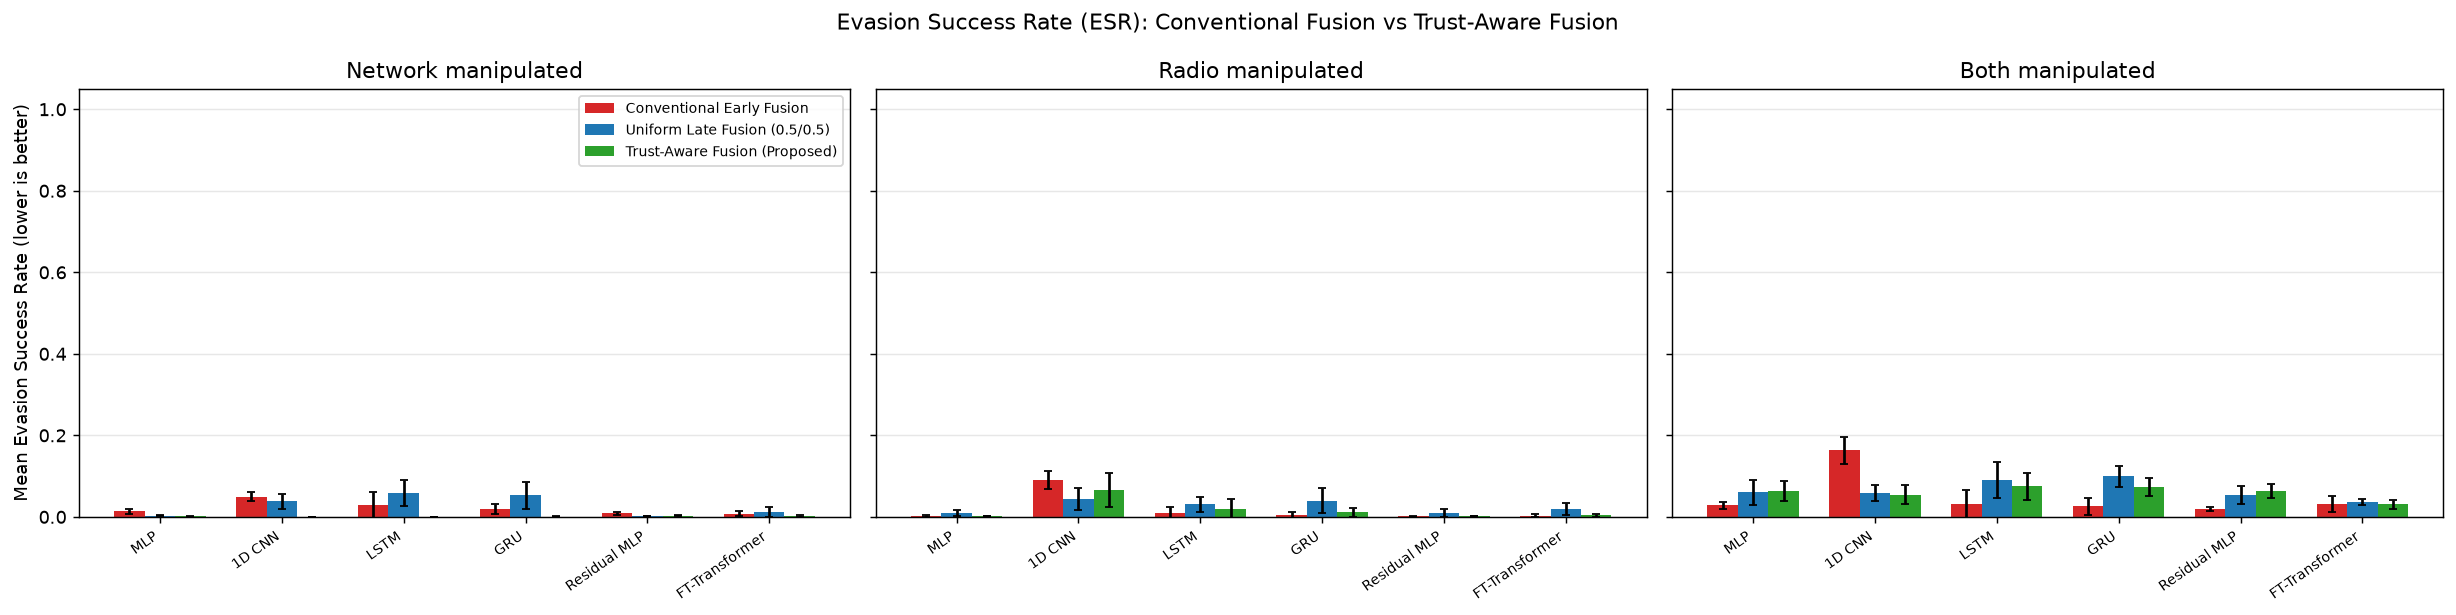

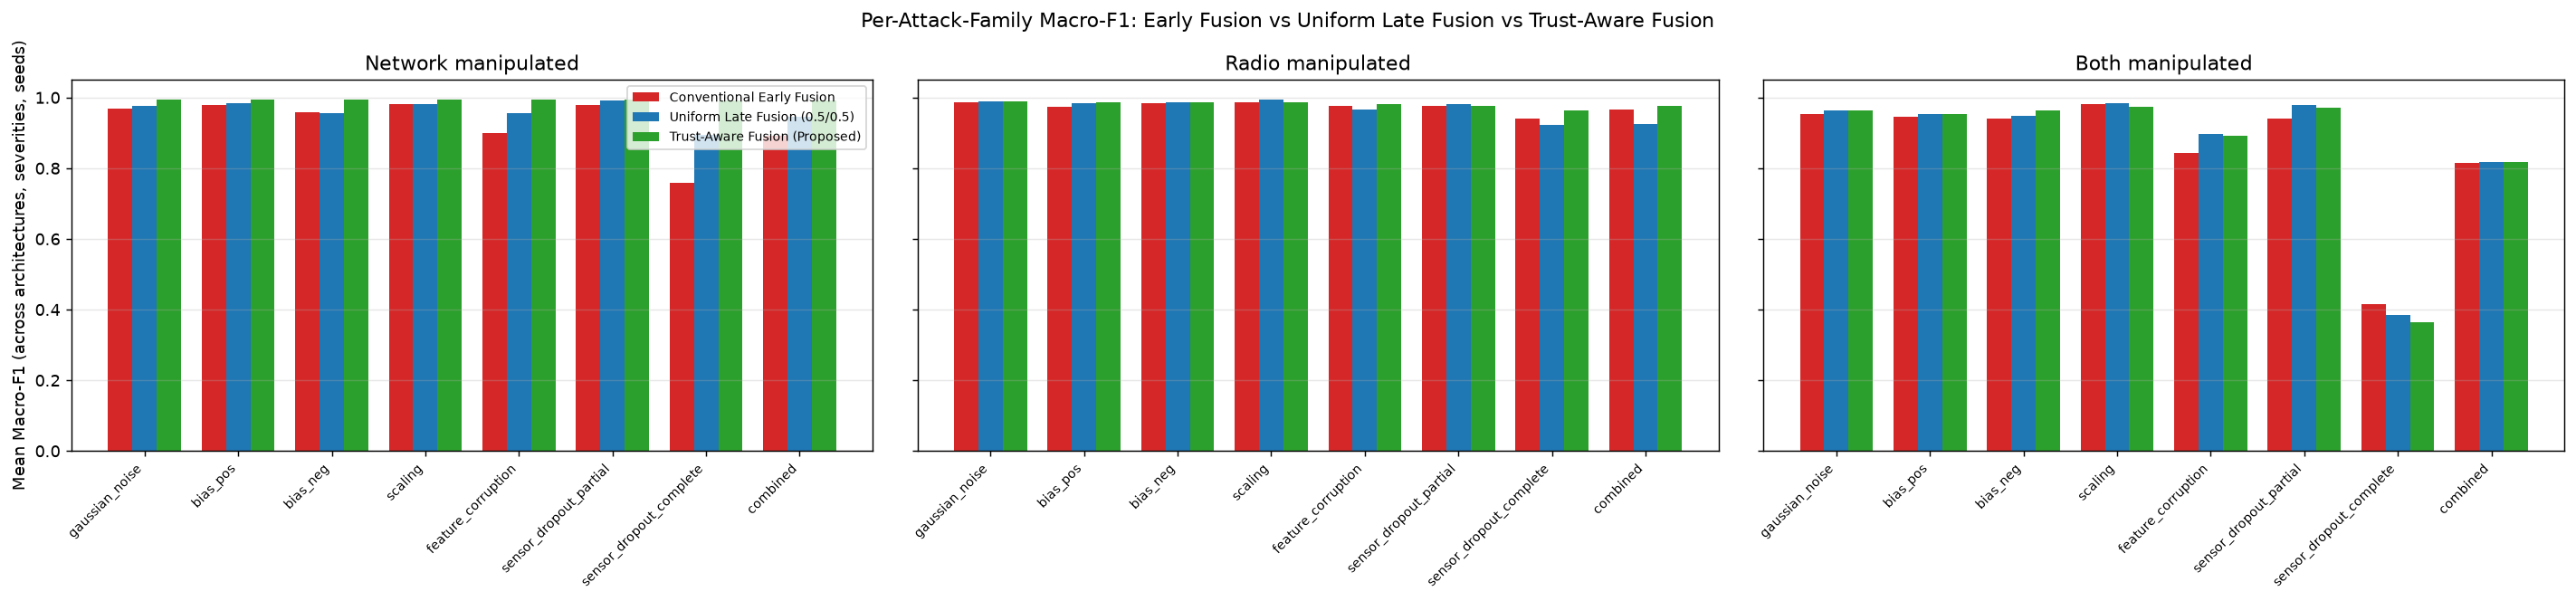

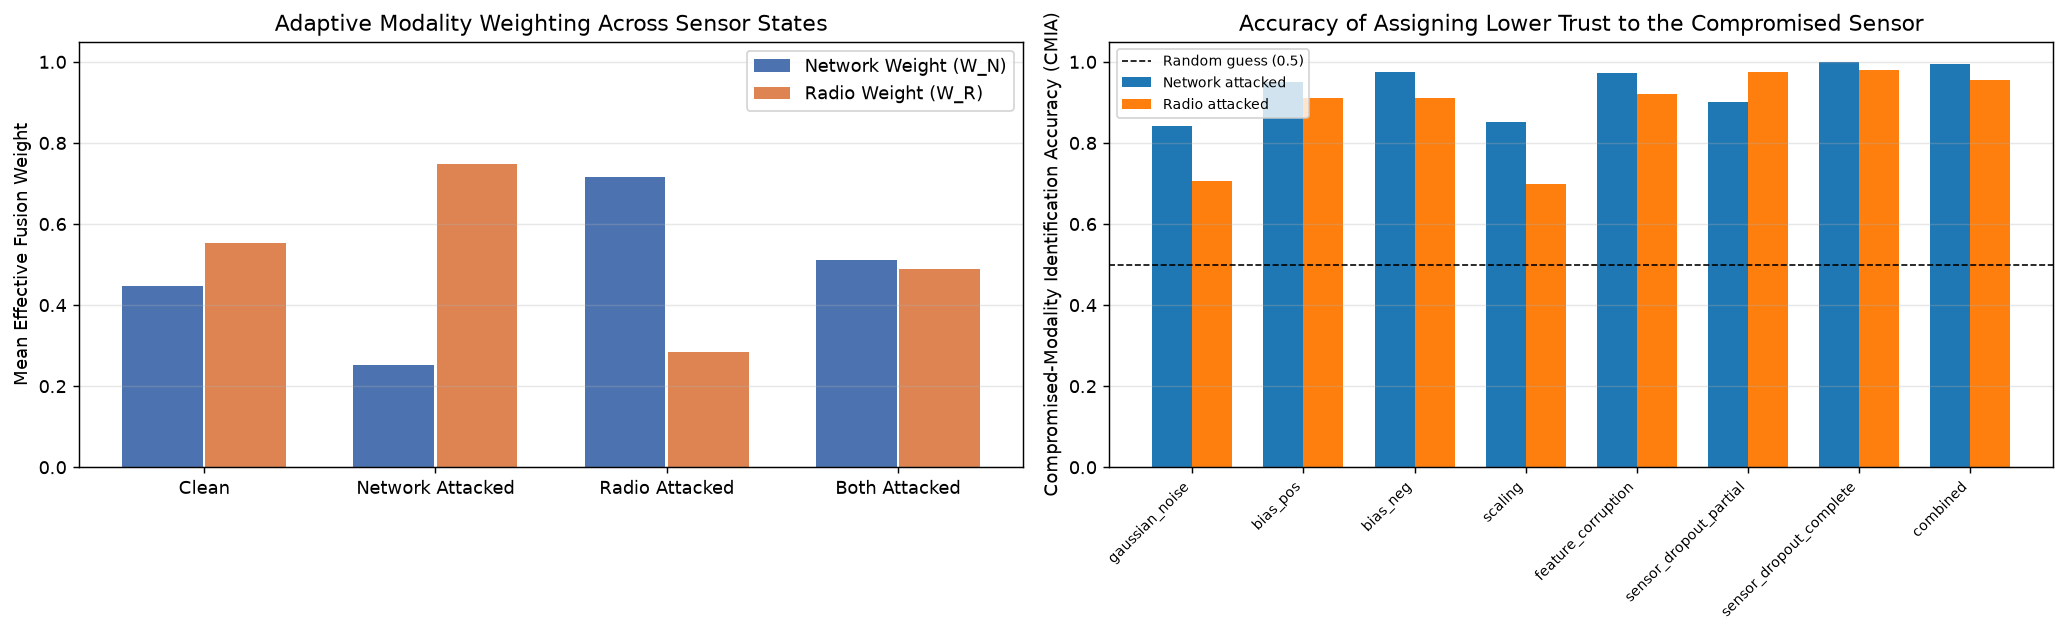

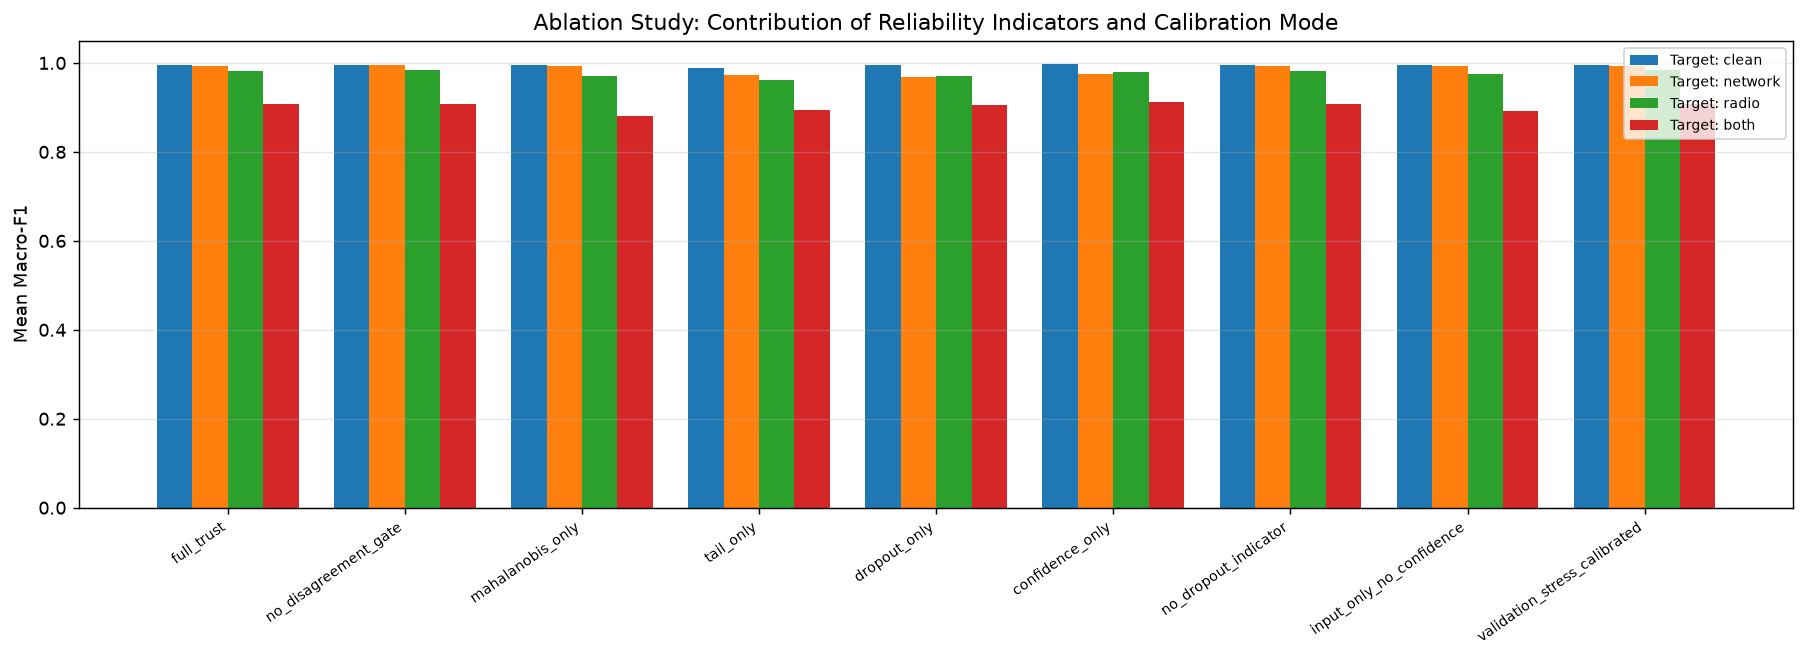

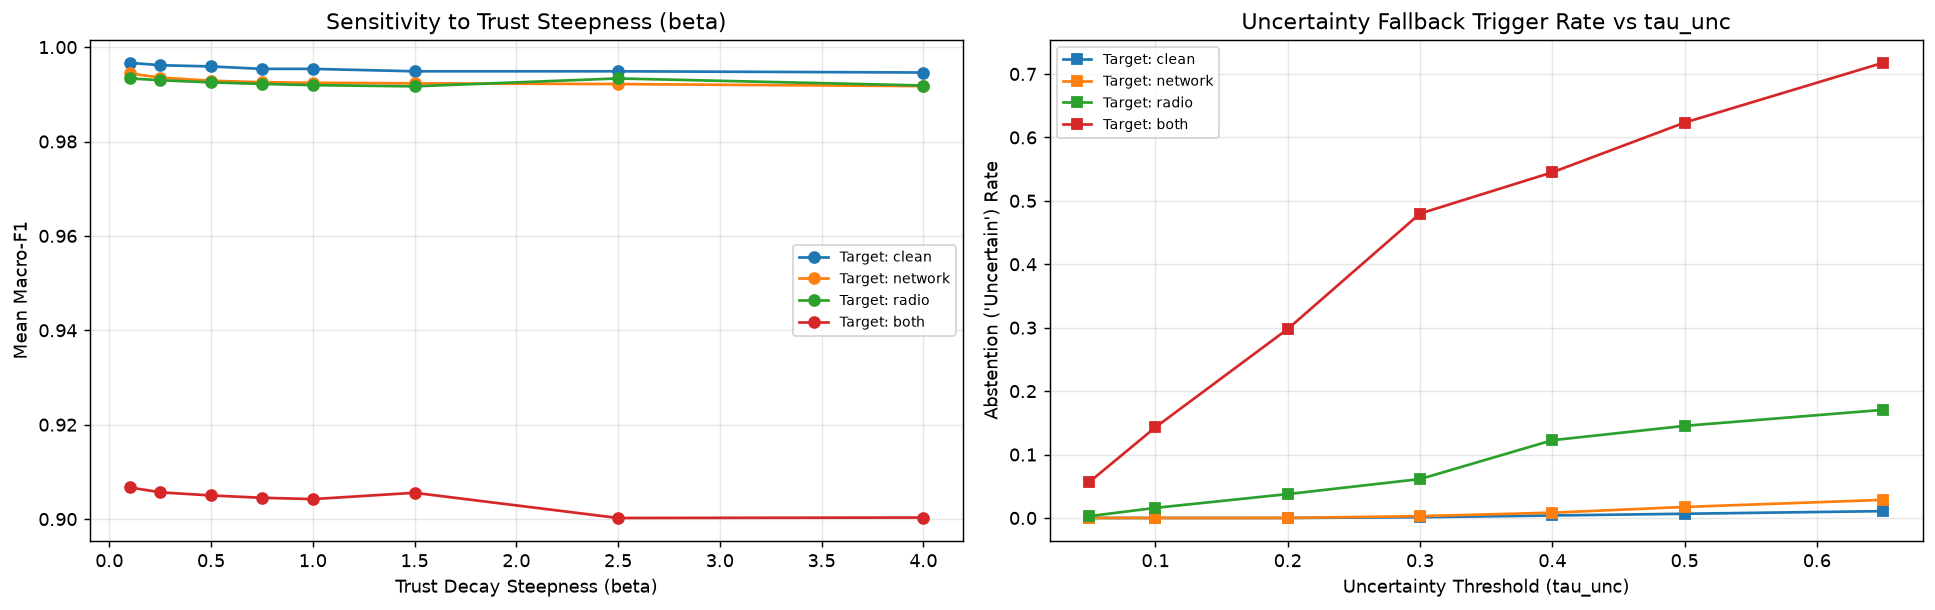

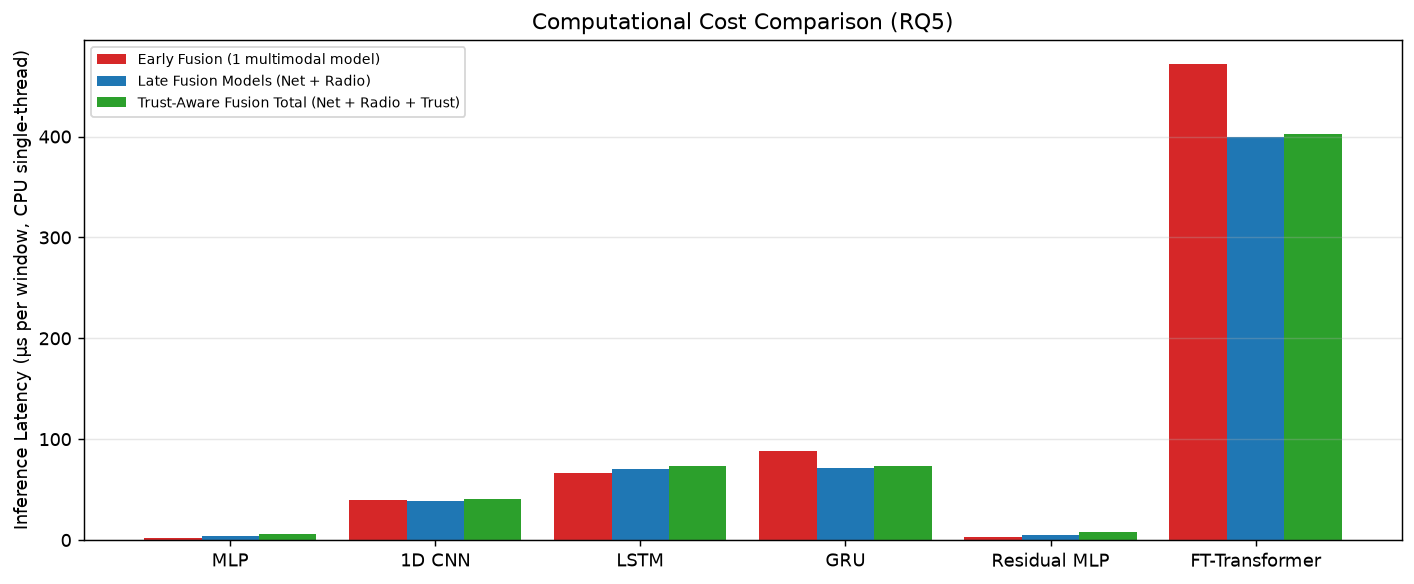

In [14]:
PLOTS = []
def save_fig(fig, name):
    fig.savefig(OUT / name, dpi=130, bbox_inches="tight")
    plt.close(fig)
    PLOTS.append(name)
    display(Image(filename=str(OUT / name)))

# Fig 1: Method comparison across Network / Radio / Both manipulation (Macro-F1)
fig, axes = plt.subplots(1, 3, figsize=(21, 5.0), sharey=True)
for ax, tgt in zip(axes, ["network", "radio", "both"]):
    x = np.arange(len(ARCHS))
    w = 0.16
    for j, m in enumerate(METHODS):
        d = COND_SEED[(COND_SEED.attack_target == tgt) & (COND_SEED.method == m)].groupby("architecture")["macro_f1"].agg(["mean", "std"]).reindex(ARCHS)
        ax.bar(x + (j - 2) * w, d["mean"], w, yerr=d["std"].fillna(0), capsize=2, color=METHOD_COLORS[m], label=METHOD_LABEL[m])
    ax.set_xticks(x); ax.set_xticklabels([ARCH_LABEL[a] for a in ARCHS], rotation=35, ha="right", fontsize=8)
    ax.set_title(f"{tgt.capitalize()} sensor manipulated", fontsize=10)
    ax.set_ylim(0, 1.05); ax.grid(axis="y", alpha=0.3)
axes[0].set_ylabel("Mean Macro-F1 across 22 attacks")
axes[0].legend(fontsize=7, loc="lower left")
fig.suptitle("Trust-Aware Fusion vs Baselines under Inference-Time Telemetry Manipulation (mean ± std over 5 seeds)", fontsize=12)
fig.tight_layout()
save_fig(fig, "fig_method_comparison_macro_f1.png")

# Fig 2: ESR comparison (Early Fusion vs Uniform Late vs Trust-Aware Fusion)
fig, axes = plt.subplots(1, 3, figsize=(19, 4.8), sharey=True)
for ax, tgt in zip(axes, ["network", "radio", "both"]):
    x = np.arange(len(ARCHS)); w = 0.25
    for j, m in enumerate(["early_fusion", "uniform_late_fusion", "trust_aware_fusion"]):
        d = COND_SEED[(COND_SEED.attack_target == tgt) & (COND_SEED.method == m)].groupby("architecture")["esr"].agg(["mean", "std"]).reindex(ARCHS)
        ax.bar(x + (j - 1) * w, d["mean"], w, yerr=d["std"].fillna(0), capsize=2, color=METHOD_COLORS[m], label=METHOD_LABEL[m])
    ax.set_xticks(x); ax.set_xticklabels([ARCH_LABEL[a] for a in ARCHS], rotation=35, ha="right", fontsize=8)
    ax.set_title(f"{tgt.capitalize()} manipulated"); ax.set_ylim(0, 1.05); ax.grid(axis="y", alpha=0.3)
axes[0].set_ylabel("Mean Evasion Success Rate (lower is better)"); axes[0].legend(fontsize=8)
fig.suptitle("Evasion Success Rate (ESR): Conventional Fusion vs Trust-Aware Fusion", fontsize=12)
fig.tight_layout()
save_fig(fig, "fig_esr_comparison.png")

# Fig 3: Attack-family breakdown (averaged across architectures & seeds)
fig, axes = plt.subplots(1, 3, figsize=(22, 5.2), sharey=True)
for ax, tgt in zip(axes, ["network", "radio", "both"]):
    x = np.arange(len(FAMILY_ORDER)); w = 0.26
    for j, m in enumerate(["early_fusion", "uniform_late_fusion", "trust_aware_fusion"]):
        d = MAIN_DF[(MAIN_DF.attack_target == tgt) & (MAIN_DF.method == m)].groupby("attack_type")["macro_f1"].mean().reindex(FAMILY_ORDER)
        ax.bar(x + (j - 1) * w, d.values, w, color=METHOD_COLORS[m], label=METHOD_LABEL[m])
    ax.set_xticks(x); ax.set_xticklabels(FAMILY_ORDER, rotation=45, ha="right", fontsize=8)
    ax.set_title(f"{tgt.capitalize()} manipulated"); ax.set_ylim(0, 1.05); ax.grid(axis="y", alpha=0.3)
axes[0].set_ylabel("Mean Macro-F1 (across architectures, severities, seeds)"); axes[0].legend(fontsize=8)
fig.suptitle("Per-Attack-Family Macro-F1: Early Fusion vs Uniform Late Fusion vs Trust-Aware Fusion", fontsize=12)
fig.tight_layout()
save_fig(fig, "fig_attack_family_comparison.png")

# Fig 4: Trust weight adaptation & compromised-modality identification (CMIA)
fig, axes = plt.subplots(1, 2, figsize=(16, 5.0))
# Left: Mean effective weight W_N and W_R across sensor states
states = ["clean", "network", "radio", "both"]
wn_vals = [CLEAN_COMP[CLEAN_COMP.method == "trust_aware_fusion"]["mean_weight_net"].mean()] + [
    MAIN_DF[(MAIN_DF.method == "trust_aware_fusion") & (MAIN_DF.attack_target == t)]["mean_weight_net"].mean() for t in ["network", "radio", "both"]
]
wr_vals = [CLEAN_COMP[CLEAN_COMP.method == "trust_aware_fusion"]["mean_weight_rad"].mean()] + [
    MAIN_DF[(MAIN_DF.method == "trust_aware_fusion") & (MAIN_DF.attack_target == t)]["mean_weight_rad"].mean() for t in ["network", "radio", "both"]
]
x = np.arange(len(states))
axes[0].bar(x - 0.18, wn_vals, 0.35, label="Network Weight (W_N)", color="#4C72B0")
axes[0].bar(x + 0.18, wr_vals, 0.35, label="Radio Weight (W_R)", color="#DD8452")
axes[0].set_xticks(x); axes[0].set_xticklabels(["Clean", "Network Attacked", "Radio Attacked", "Both Attacked"])
axes[0].set_ylabel("Mean Effective Fusion Weight"); axes[0].set_ylim(0, 1.05)
axes[0].set_title("Adaptive Modality Weighting Across Sensor States"); axes[0].legend(); axes[0].grid(axis="y", alpha=0.3)

# Right: CMIA by attack family
x2 = np.arange(len(FAMILY_ORDER)); w2 = 0.36
for j, tgt in enumerate(["network", "radio"]):
    d = MAIN_DF[(MAIN_DF.method == "trust_aware_fusion") & (MAIN_DF.attack_target == tgt)].groupby("attack_type")["cmia"].mean().reindex(FAMILY_ORDER)
    axes[1].bar(x2 + (j - 0.5) * w2, d.values, w2, label=f"{tgt.capitalize()} attacked")
axes[1].axhline(0.5, color="k", ls="--", lw=0.9, label="Random guess (0.5)")
axes[1].set_xticks(x2); axes[1].set_xticklabels(FAMILY_ORDER, rotation=45, ha="right", fontsize=8)
axes[1].set_ylabel("Compromised-Modality Identification Accuracy (CMIA)"); axes[1].set_ylim(0, 1.05)
axes[1].set_title("Accuracy of Assigning Lower Trust to the Compromised Sensor"); axes[1].legend(fontsize=8); axes[1].grid(axis="y", alpha=0.3)
fig.tight_layout()
save_fig(fig, "fig_trust_weights_and_cmia.png")

# Fig 5: Ablation study bar chart
fig, ax = plt.subplots(figsize=(14, 5.2))
abl_order = list(tfm.ABLATION_PRESETS.keys()) + ["validation_stress_calibrated"]
x = np.arange(len(abl_order)); w = 0.20
for j, tgt in enumerate(["clean", "network", "radio", "both"]):
    d = ABL_DF[ABL_DF.attack_target == tgt].groupby("ablation")["macro_f1"].mean().reindex(abl_order)
    ax.bar(x + (j - 1.5) * w, d.values, w, label=f"Target: {tgt}")
ax.set_xticks(x); ax.set_xticklabels(abl_order, rotation=35, ha="right", fontsize=8)
ax.set_ylabel("Mean Macro-F1"); ax.set_ylim(0, 1.05)
ax.set_title("Ablation Study: Contribution of Reliability Indicators and Calibration Mode")
ax.legend(fontsize=8); ax.grid(axis="y", alpha=0.3); fig.tight_layout()
save_fig(fig, "fig_ablation_study.png")

# Fig 6: Sensitivity curves (beta and tau_unc)
fig, axes = plt.subplots(1, 2, figsize=(15, 4.8))
for tgt in ["clean", "network", "radio", "both"]:
    d = SENS_BETA_DF[SENS_BETA_DF.attack_target == tgt].groupby("beta")["macro_f1"].mean()
    axes[0].plot(d.index, d.values, marker="o", label=f"Target: {tgt}")
axes[0].set_xlabel("Trust Decay Steepness (beta)"); axes[0].set_ylabel("Mean Macro-F1")
axes[0].set_title("Sensitivity to Trust Steepness (beta)"); axes[0].legend(fontsize=8); axes[0].grid(alpha=0.3)

for tgt in ["clean", "network", "radio", "both"]:
    d = SENS_TAU_DF[SENS_TAU_DF.attack_target == tgt].groupby("tau_unc")["abstain_rate"].mean()
    axes[1].plot(d.index, d.values, marker="s", label=f"Target: {tgt}")
axes[1].set_xlabel("Uncertainty Threshold (tau_unc)"); axes[1].set_ylabel("Abstention ('Uncertain') Rate")
axes[1].set_title("Uncertainty Fallback Trigger Rate vs tau_unc"); axes[1].legend(fontsize=8); axes[1].grid(alpha=0.3)
fig.tight_layout()
save_fig(fig, "fig_sensitivity_analysis.png")

# Fig 7: Inference latency breakdown
fig, ax = plt.subplots(figsize=(11, 4.6))
x = np.arange(len(ARCHS)); w = 0.28
lat_idx = LAT_DF.set_index("architecture").reindex(ARCHS)
ax.bar(x - w, lat_idx["early_fusion_us_per_window"], w, label="Early Fusion (1 multimodal model)", color="#D62728")
ax.bar(x,     lat_idx["trust_fusion_total_us_per_window"] - lat_idx["trust_scoring_us_per_window"], w, label="Late Fusion Models (Net + Radio)", color="#1F77B4")
ax.bar(x + w, lat_idx["trust_fusion_total_us_per_window"], w, label="Trust-Aware Fusion Total (Net + Radio + Trust)", color="#2CA02C")
ax.set_xticks(x); ax.set_xticklabels([ARCH_LABEL[a] for a in ARCHS])
ax.set_ylabel("Inference Latency (µs per window, CPU single-thread)")
ax.set_title("Computational Cost Comparison (RQ5)")
ax.legend(fontsize=8); ax.grid(axis="y", alpha=0.3); fig.tight_layout()
save_fig(fig, "fig_inference_latency.png")


 ## 14. Automated report generation & end-to-end verification

In [15]:
def _fmt(v, nd=4):
    if isinstance(v, (int, np.integer)): return f"{int(v):,}"
    if isinstance(v, (float, np.floating)): return "n/a" if np.isnan(v) else f"{v:.{nd}f}"
    return str(v)

def md_table(d, nd=4):
    cols = [str(c) for c in d.columns]
    lines = ["| " + " | ".join(cols) + " |", "|" + "|".join("---" for _ in cols) + "|"]
    for row in d.itertuples(index=False):
        lines.append("| " + " | ".join(_fmt(v, nd) for v in row) + " |")
    return "\n".join(lines)

# Summary report (all numbers dynamically computed from measured tables)
L = []
A = L.append
A("# Trust-Aware Multimodal Fusion — Experimental Report"); A("")
A("**Project:** *When One Sensor Lies: Robust Multimodal Intrusion Detection Against Inference-Time Telemetry Manipulation in 5G Open RAN*"); A("")
A("> All perturbations are synthetic, label-independent stress tests in standardised feature space (`ATTACK_SEED = 20260`). Reliability estimators were fitted strictly on `train` (2,702 windows) and calibrated strictly on clean `validation` (635 windows); `test` (802 windows) was never used for fitting or tuning."); A("")

A("## 1. Clean-Data Performance (RQ5)"); A("")
clean_rep = CLEAN_COMP.groupby("method")[["accuracy", "macro_f1", "recall", "fpr", "pr_auc", "abstain_rate"]].mean().reindex(METHODS).reset_index()
A(md_table(clean_rep)); A("")

A("## 2. Overall Robustness Under Telemetry Manipulation (RQ4)"); A("")
rob_rep = COND_SEED.groupby(["attack_target", "method"])[["macro_f1", "delta_macro_f1", "recall", "fpr", "esr", "cmia", "abstain_rate", "selective_macro_f1"]].mean().reset_index()
A(md_table(rob_rep)); A("")

A("## 3. Ablation Study Summary"); A("")
abl_rep = ABL_DF.groupby(["ablation", "attack_target"])["macro_f1"].mean().unstack("attack_target")[["clean", "network", "radio", "both"]].reset_index()
A(md_table(abl_rep)); A("")

A("## 4. Inference Latency Benchmark (CPU, single-thread, RQ5)"); A("")
A(md_table(LAT_DF[["architecture", "early_fusion_us_per_window", "trust_scoring_us_per_window", "trust_fusion_total_us_per_window", "overhead_vs_early_ratio", "trust_overhead_vs_late_pct"]], nd=2)); A("")

A("## 5. Limitations"); A("")
A("* Only 35 scenarios exist in total; the test partition contains 1 benign scenario (229 benign windows, 573 attack windows), so test FPR resolution is 1/229.")
A("* Capture date/session is confounded with class in the underlying dataset; scenario-based splitting does not eliminate session confounding.")
A("* All manipulations are synthetic stress tests in standardised space and are not validated physical 5G O-RAN attacks.")
A("* When BOTH sensors are severely corrupted simultaneously, no honest modality remains to recover ground truth; the uncertainty fallback is intended to abstain rather than force an unreliable prediction.")

(OUT / "trust_fusion_report.md").write_text("\n".join(L), encoding="utf-8")

# End-to-end verification suite
VER = []
def chk(name, ok, detail=""):
    VER.append({"check": name, "passed": bool(ok), "detail": str(detail)[:160]})

expected_csvs = [
    "validation_calibration_summary.csv",
    "clean_comparison_per_seed.csv",
    "trust_fusion_results_per_seed.csv",
    "trust_fusion_results_summary.csv",
    "trust_fusion_condition_summary_per_seed.csv",
    "trust_fusion_scenario_results.csv",
    "ablation_results_per_seed.csv",
    "sensitivity_beta.csv",
    "sensitivity_tau_unc.csv",
    "inference_latency_benchmark.csv",
    "trust_fusion_report.md",
]
for f in expected_csvs:
    chk(f"output exists: {f}", (OUT / f).exists() and (OUT / f).stat().st_size > 0)
for p in PLOTS:
    chk(f"plot exists: {p}", (OUT / p).exists())

# Verify zero mutation of pre-existing project files
HASH_AFTER = {k: sha256_file(ROOT / k) for k in HASH_BEFORE}
chk("zero pre-existing project files modified", HASH_AFTER == HASH_BEFORE, [k for k in HASH_AFTER if HASH_AFTER[k] != HASH_BEFORE[k]])

# Verify completeness and numerical sanity
exp_main = len(RUNNABLE_PAIRS) * len(ATTACK_GRID) * 3 * len(METHODS)
chk("main results row count matches full grid", len(MAIN_DF) == exp_main, f"{len(MAIN_DF)} vs {exp_main}")
chk("confusion matrices sum to n_test", ((MAIN_DF.tn + MAIN_DF.fp + MAIN_DF.fn + MAIN_DF.tp) == MAIN_DF.n_test).all())
chk("trust scores and weights bounded in [0, 1]",
    MAIN_DF.loc[MAIN_DF.method == "trust_aware_fusion", ["mean_trust_net", "mean_trust_rad", "mean_weight_net", "mean_weight_rad"]].stack().between(0, 1).all())

VERIFY_DF = pd.DataFrame(VER)
display(VERIFY_DF)
assert VERIFY_DF.passed.all(), VERIFY_DF[~VERIFY_DF.passed]
print(f"\nALL {len(VERIFY_DF)} VERIFICATION CHECKS PASSED. Outputs saved in: {OUT}")

,check,passed,detail
0,output exists: validation_calibration_summary.csv,True,
1,output exists: clean_comparison_per_seed.csv,True,
2,output exists: trust_fusion_results_per_seed.csv,True,
3,output exists: trust_fusion_results_summary.csv,True,
4,output exists: trust_fusion_condition_summary_...,True,
5,output exists: trust_fusion_scenario_results.csv,True,
6,output exists: ablation_results_per_seed.csv,True,
7,output exists: sensitivity_beta.csv,True,
8,output exists: sensitivity_tau_unc.csv,True,
9,output exists: inference_latency_benchmark.csv,True,



ALL 22 VERIFICATION CHECKS PASSED. Outputs saved in: d:\GitHub\Robust-Multimodal-Intrusion-Detection-Against-Inference-Time-Telemetry-Manipulation-in-5G-Open-RAN\Results\trust_aware_fusion
